In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

In [13]:
def display_images(images, columns=2, figsize=(8, 10)):
    rows = (len(images) + columns - 1) // columns
    plt.figure(figsize=figsize)

    for i, (title, image) in enumerate(images.items(), start=1):
        plt.subplot(rows, columns, i)
        plt.imshow(image, cmap="gray")
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# Custom binary image
binary = np.array(
    [
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 1, 1, 1, 0, 0],
        [0, 0, 1, 1, 1, 0, 0],
        [0, 0, 1, 1, 1, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0],
    ]
)

In [ ]:
def manualErosion(image, kernel, anchor=None):
    rows, cols = image.shape
    kr, kc = kernel.shape

    if anchor is None:
        anchor = (kr // 2, kc // 2)

    r, c = anchor
    pad = ((r, kr - r - 1), (c, kc - c - 1))
    padded = np.pad(image, pad, mode="constant", constant_values=0)
    
    eroded = np.zeros_like(image)
    foreground = np.max(image)

    for i in range(rows):
        for j in range(cols):
            region = padded[i : i + kr, j : j + kc]
            if np.all(region[kernel != 0] != 0):
                eroded[i, j] = foreground

    return eroded

In [ ]:
def manualDilation(image, kernel, anchor=None):
    rows, cols = image.shape
    kr, kc = kernel.shape

    if anchor is None:
        anchor = (kr // 2, kc // 2)

    r, c = anchor
    pad = ((r, kr - r - 1), (c, kc - c - 1))
    padded = np.pad(image, pad, mode="constant", constant_values=0)
    
    dilated = np.zeros_like(image)
    foreground = np.max(image)

    for i in range(rows):
        for j in range(cols):
            region = padded[i : i + kr, j : j + kc]
            if np.any(region[kernel != 0] != 0):
                dilated[i, j] = foreground

    return dilated

In [11]:
# Structuring elements

cross = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

left_diagonal = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
], dtype=np.uint8)

right_diagonal = np.array([
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
], dtype=np.uint8)

horizontal = np.array([
    [1, 1, 1]
], dtype=np.uint8)

reverse_cross = np.array([
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1]
], dtype=np.uint8)

kernel = cross

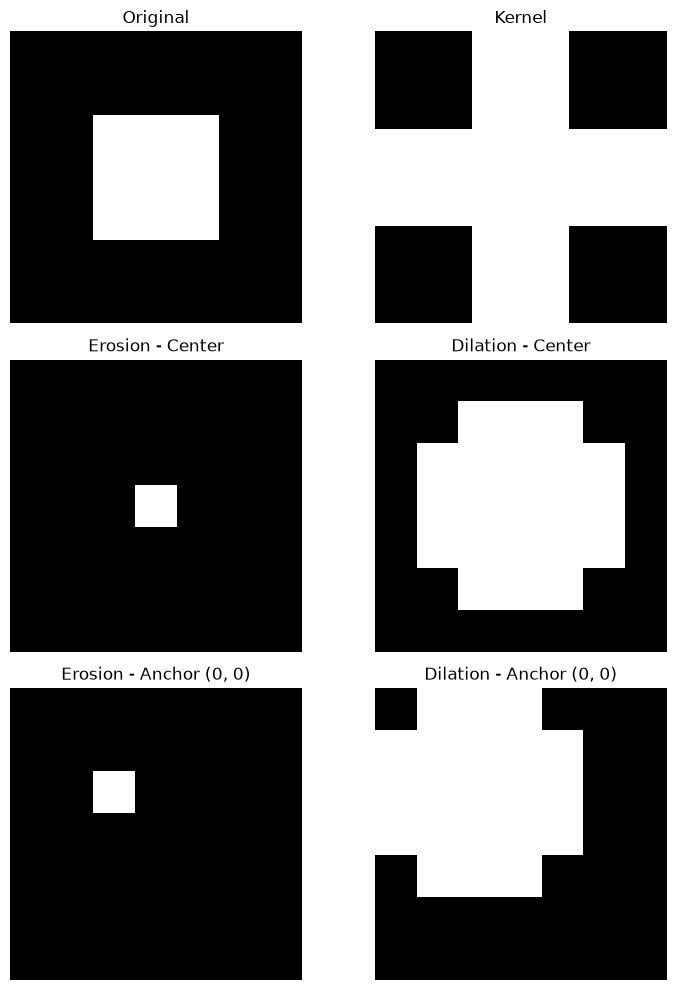

In [14]:
# Default anchor = center
eroded = manualErosion(binary, kernel)
dilated = manualDilation(binary, kernel)

# Custom anchor
anchor = (0, 0)
eroded_custom = manualErosion(binary, kernel, anchor=anchor)
dilated_custom = manualDilation(binary, kernel, anchor=anchor)

images = {
    "Original": binary,
    "Kernel": kernel,
    "Erosion - Center": eroded,
    "Dilation - Center": dilated,
    f"Erosion - Anchor {anchor}": eroded_custom,
    f"Dilation - Anchor {anchor}": dilated_custom,
}

display_images(images)